## This notebook is for testing the ChebyshevInterpolant2D class

In [1]:
import numpy as np
from scipy.fft import dctn, dct
from chebND.utils import chebyshev_nodes, chebyshev_gauss_lobatto_nodes, find_significant_coeffs_1d, find_significant_coeffs_2d
from chebND.clenshaw import clenshaw_1d, clenshaw_2d
from chebND.interp2d import ChebyshevInterpolant2D
import matplotlib.pyplot as plt
 

from scipy.fft import dct

## Parallel Python Code Definitions

In [2]:
def compute_chebyshev_coefficients_2d(func_or_vals,Nx, Ny, ax, bx, ay, by, kind='dct'):
    """
    Compute the 2D Chebyshev coefficients of a function or discrete values
    over [ax, bx] × [ay, by].

    Parameters:
        func_or_vals : callable or 2D np.ndarray
            Either a function f(x, y), or a 2D array of values sampled at Chebyshev points.
        ax, bx : float
            Domain bounds in x-direction.
        ay, by : float
            Domain bounds in y-direction.
        Nx, Ny : int
            Number of Chebyshev points in x and y directions.
        kind : str
            Currently only 'dct' is supported, using DCT-I.

    Returns:
        coeffs : 2D np.ndarray
            Array of Chebyshev coefficients.
    """

    # Generate Chebyshev nodes in x and y
    x = chebyshev_nodes(Nx, ax, bx)
    y = chebyshev_nodes(Ny, ay, by)

    if callable(func_or_vals):
        X, Y = np.meshgrid(x, y, indexing='ij')
        vals = func_or_vals(X, Y)
    else:
        vals = np.asarray(func_or_vals)
        assert vals.shape == (Nx, Ny), "Input array shape must match (Nx, Ny)"

    if kind == 'dct':
        # Compute DCT-I in both dimensions
        coeffs = dctn(vals, type=2, norm=None)
        # Normalize to match Chebyshev projection
        coeffs *= 1 / ((Nx) * (Ny))
        coeffs[0, :] *= 0.5
        coeffs[:, 0] *= 0.5
    else:
        raise ValueError("Only 'dct' is supported for now.")

    return coeffs

In [54]:
def renormalise_dctn_extrema(C):
    """
    Renormalise the output of an unnormalised DCT-I (scipy.fft.dctn with type=1, norm=None)
    so that it matches the standard Chebyshev coefficient convention.

    Parameters
    ----------
    C : ndarray
        Raw coefficients from dctn(..., type=1, norm=None).
        Shape (N1, N2, ..., Nd).

    Returns
    -------
    coeffs : ndarray
        Chebyshev coefficients with standard convention.
    """
    shape = C.shape
    ndim = C.ndim

    # overall scaling
    scale = np.prod([N - 1 for N in shape], dtype=float)

    # build factor array per axis (2 at endpoints, 1 otherwise)
    factors = []
    for N in shape:
        f = np.ones(N, dtype=float)
        f[0] = 2.0
        f[-1] = 2.0
        factors.append(f)

    # combine factors by broadcasting (outer product over all axes)
    factor_array = factors[0]
    for f in factors[1:]:
        factor_array = np.multiply.outer(factor_array, f)

    # normalised coefficients
    coeffs = C / (scale * factor_array)
    return coeffs

In [55]:
def compute_chebyshev_coefficients_2d_GL(vals,ax, bx, ay, by,kind='nodes'):
    """
    Compute the 2D Chebyshev coefficients of a function or discrete values
    over [ax, bx] × [ay, by].

    Parameters:
        func_or_vals : callable or 2D np.ndarray
            Either a function f(x, y), or a 2D array of values sampled at Chebyshev points.
        ax, bx : float
            Domain bounds in x-direction.
        ay, by : float
            Domain bounds in y-direction.
        Nx, Ny : int
            Number of Chebyshev points in x and y directions.
        kind : str
            Currently only 'dct' is supported, using DCT-I.

    Returns:
        coeffs : 2D np.ndarray
            Array of Chebyshev coefficients.
    """
    Nx, Ny = vals.shape
    # Generate Chebyshev nodes in x and y
    x = chebyshev_nodes(Nx, ax, bx)
    y = chebyshev_nodes(Ny, ay, by)

    ceoffs = np.zeros((Nx,Ny))

    if kind == 'nodes':
        # Compute DCT-II in both dimensions
        coeffs = dctn(vals, type=2, norm=None)
        # Normalize to match Chebyshev projection
        coeffs *= 1 / ((Nx) * (Ny))
        coeffs[0, :] *= 0.5
        coeffs[:, 0] *= 0.5
    elif kind == 'GL':
        # Compute DCT-I in both dimensions
        coeffs = dctn(vals, type=1, norm=None)
        # Normalize to match Chebyshev projection
        #coeffs *= 1 / ((Nx-1) * (Ny-1))
        #coeffs[0, :] *= 0.5
        #coeffs[-1, :] *= 0.5
        #coeffs[:, 0] *= 0.5
        #coeffs[:, -1] *= 0.5
        coeffs = renormalise_dctn_extrema(coeffs)

    else:
        raise ValueError("Only 'dct' is supported for now.")

    return coeffs

In [4]:
# A function that computes chebyshev polynomial coefficients for a 2D interpolant using scipy's dctn function



In [5]:

def clenshaw_1D(coeffs, x,  k_max=None, a=-1.0, b=1.0):
    """
    Evaluate Chebyshev series at a single point x using Clenshaw's algorithm.
    
    Parameters:
        coeffs: array of Chebyshev coefficients
        x: point of evaluation in [a, b]
        a, b: domain bounds (default [-1, 1])
        k_max : int, optional
            Number of coefficients to use (truncate at this order).
            Defaults to len(coeffs).
    
    Returns:
        interpolated value at x
    """
    if k_max is None:
        k_max = len(coeffs)
    
    
    # Map x from [a, b] to [-1, 1]
    xt = (2.0 * x - a - b) / (b - a)
    
    b_k1 = 0.0
    b_k2 = 0.0
    for k in range(k_max-1, 0, -1):
        b_k = 2 * xt * b_k1 - b_k2 + coeffs[k]
        b_k2 = b_k1
        b_k1 = b_k
    return coeffs[0] + xt * b_k1 - b_k2


def clenshaw_2D(coeffs, x, y, NyMaxes = None, ax = -1., bx=1, ay=-1., by=1.):
    """
    Evaluate a 2D Chebyshev interpolant using the Clenshaw algorithm.

    Parameters:

        coeffs : 2D np.ndarray
            Matrix of Chebyshev coefficients [Nx, Ny].
        x, y : float
            Point to evaluate.
        Nx : int, optional
            Number of Chebyshev points in x-direction. If None, defaults to shape(coeffs)[0].
        Ny : int, optional
            Number of Chebyshev points in y-direction. If None, defaults to shape(coeffs)[1].
        ax, bx : float
            Domain bounds in x-direction.
        ay, by : float
            Domain bounds in y-direction.

    Returns:
        float
            Value of interpolant at (x, y)
    """
    if NyMaxes is None:
        NyMaxes = np.ones(coeffs.shape[0], dtype=np.int64) * coeffs.shape[1]

    # Map x, y from [ax, bx] and [ay, by] to [-1, 1]
    tx = (2 * x - (bx + ax)) / (bx - ax)
    ty = (2 * y - (by + ay)) / (by - ay)

    # Evaluate in y-direction first for each fixed x
    temp = np.array([clenshaw_1D(coeffs[i, :], ty,NyMaxes[i]) for i in range(NyMaxes.shape[0])])
    
    # Then evaluate resulting 1D Chebyshev series in x-direction
    return clenshaw_1D(temp, tx,NyMaxes.shape[0])

## Testing

In [47]:
# Define a smooth function
def f(x, y):
    return np.exp(-x**2 - y**2)

# Bounds and resolution
ax, bx = -2, 3
ay, by = -2, 1
Nx, Ny = 50, 50

# Generate Chebyshev nodes and compute coefficients
x_nodes = chebyshev_nodes(Nx, ax, bx)
y_nodes = chebyshev_nodes(Ny, ay, by)

X, Y = np.meshgrid(x_nodes, y_nodes, indexing='ij')
vals = f(X, Y)


In [48]:
x_nodes

array([ 2.9987664 ,  2.98890491,  2.96922085,  2.9397919 ,  2.90073421,
        2.85220192,  2.79438656,  2.72751631,  2.65185507,  2.56770144,
        2.47538753,  2.37527767,  2.26776695,  2.15327966,  2.03226763,
        1.90520844,  1.77260354,  1.63497625,  1.49286973,  1.3468448 ,
        1.19747777,  1.0453581 ,  0.89108616,  0.73527078,  0.5785269 ,
        0.4214731 ,  0.26472922,  0.10891384, -0.0453581 , -0.19747777,
       -0.3468448 , -0.49286973, -0.63497625, -0.77260354, -0.90520844,
       -1.03226763, -1.15327966, -1.26776695, -1.37527767, -1.47538753,
       -1.56770144, -1.65185507, -1.72751631, -1.79438656, -1.85220192,
       -1.90073421, -1.9397919 , -1.96922085, -1.98890491, -1.9987664 ])

In [49]:
# Generate Chebyshev nodes and compute coefficients
x_GL = chebyshev_gauss_lobatto_nodes(Nx, ax, bx)
y_GL = chebyshev_gauss_lobatto_nodes(Ny, ay, by)

X2, Y2 = np.meshgrid(x_GL, y_GL, indexing='ij')
vals2 = f(X2, Y2)

In [50]:
x_GL

array([ 3.        ,  2.99486348,  2.97947503,  2.95389789,  2.91823716,
        2.87263937,  2.81729189,  2.75242217,  2.67829676,  2.59522026,
        2.50353405,  2.4036149 ,  2.29587338,  2.18075223,  2.0587245 ,
        1.93029165,  1.79598142,  1.65634573,  1.51195836,  1.36341264,
        1.21131897,  1.05630233,  0.89899974,  0.74005756,  0.58012894,
        0.41987106,  0.25994244,  0.10100026, -0.05630233, -0.21131897,
       -0.36341264, -0.51195836, -0.65634573, -0.79598142, -0.93029165,
       -1.0587245 , -1.18075223, -1.29587338, -1.4036149 , -1.50353405,
       -1.59522026, -1.67829676, -1.75242217, -1.81729189, -1.87263937,
       -1.91823716, -1.95389789, -1.97947503, -1.99486348, -2.        ])

In [51]:
vals2.shape

(50, 50)

In [52]:
coeffs = compute_chebyshev_coefficients_2d_GL(vals,ax, bx, ay, by, kind='nodes')
print(coeffs)

[[ 1.10033474e-01  7.88451315e-02 -7.17832039e-02 ... -2.84217094e-18
  -5.68434189e-18  5.68434189e-18]
 [-5.00325406e-02 -3.58511106e-02  3.26400316e-02 ...  1.42108547e-18
   0.00000000e+00  2.84217094e-18]
 [-1.57102751e-01 -1.12572898e-01  1.02490073e-01 ...  0.00000000e+00
   2.27373675e-17  0.00000000e+00]
 ...
 [ 9.37028233e-18  7.97949832e-18 -5.19253148e-18 ... -1.66108890e-18
   5.05044992e-19  2.96216434e-18]
 [-6.56141808e-18 -6.72470459e-18  5.53100812e-19 ... -5.21051426e-19
  -1.05791596e-18 -8.40138786e-20]
 [ 4.12447854e-18  2.45829371e-18 -1.83887024e-18 ... -3.12552438e-19
   1.16980158e-19 -6.62366680e-19]]


In [56]:
coeffs2 = compute_chebyshev_coefficients_2d_GL(vals2,ax, bx, ay, by, kind='GL')
print(coeffs2)

[[ 1.10033474e-01  7.88451315e-02 -7.17832039e-02 ... -5.91872333e-18
   0.00000000e+00  0.00000000e+00]
 [-5.00325406e-02 -3.58511106e-02  3.26400316e-02 ... -2.95936166e-18
   2.95936166e-18  5.91872333e-18]
 [-1.57102751e-01 -1.12572898e-01  1.02490073e-01 ...  0.00000000e+00
   0.00000000e+00  0.00000000e+00]
 ...
 [ 1.45887282e-17  1.06805035e-17 -9.04422183e-18 ...  4.51353676e-19
  -8.59921451e-19 -1.08664061e-18]
 [ 2.26865128e-18  3.02240055e-18 -7.54387016e-20 ...  5.23175164e-19
   6.85880741e-19 -5.49100309e-20]
 [-6.54007368e-18 -4.40118378e-18  3.72574967e-18 ... -6.14197626e-19
   2.04185363e-18  1.66175093e-18]]


In [57]:
coeffs2[0,0]/coeffs[0,0]

np.float64(0.9999999999999999)

In [58]:
coeffs2[3,0]/coeffs[3,0]

np.float64(1.0000000000000002)

In [59]:
coeffs2[0,3]/coeffs[0,3]

np.float64(0.9999999999999999)

In [61]:
print(coeffs-coeffs2)

[[ 1.38777878e-17  1.38777878e-17  0.00000000e+00 ...  3.07655239e-18
  -5.68434189e-18  5.68434189e-18]
 [ 6.93889390e-18  0.00000000e+00 -6.93889390e-18 ...  4.38044714e-18
  -2.95936166e-18 -3.07655239e-18]
 [ 0.00000000e+00  2.77555756e-17  0.00000000e+00 ...  0.00000000e+00
   2.27373675e-17  0.00000000e+00]
 ...
 [-5.21844588e-18 -2.70100521e-18  3.85169035e-18 ... -2.11244257e-18
   1.36496644e-18  4.04880495e-18]
 [-8.83006935e-18 -9.74710514e-18  6.28539514e-19 ... -1.04422659e-18
  -1.74379670e-18 -2.91038478e-20]
 [ 1.06645522e-17  6.85947749e-18 -5.56461991e-18 ...  3.01645188e-19
  -1.92487347e-18 -2.32411762e-18]]


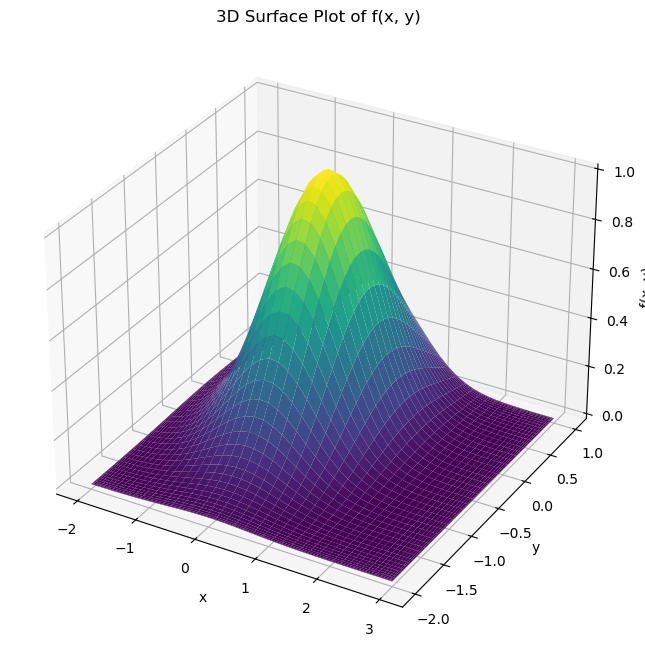

In [43]:
# Create a 3D plot of the function
fig = plt.figure(figsize=(10, 8))
ax1 = fig.add_subplot(111, projection='3d')
ax1.plot_surface(X, Y, vals, cmap='viridis', edgecolor='none')

ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_zlabel('f(x, y)')
ax1.set_title('3D Surface Plot of f(x, y)')

plt.show()

In [62]:
# Evaluate at some point
x_eval, y_eval = 1, -0.5
approx = clenshaw_2d(coeffs, x_eval, y_eval,NyMaxes=None, ax = ax,bx =bx,ay=ay,by=by)

# Compare to exact value
true_val = f(x_eval, y_eval)
error = abs(true_val - approx)

print(f"Approximation: {approx}")
print(f"True value:    {true_val}")
print(f"Absolute error: {error:.2e}")

Approximation: 0.28650479686019015
True value:    0.2865047968601901
Absolute error: 5.55e-17


In [63]:
# Evaluate at some point
x_eval, y_eval = 1, -0.5
approx = clenshaw_2d(coeffs2, x_eval, y_eval,NyMaxes=None, ax = ax,bx =bx,ay=ay,by=by)

# Compare to exact value
true_val = f(x_eval, y_eval)
error = abs(true_val - approx)

print(f"Approximation: {approx}")
print(f"True value:    {true_val}")
print(f"Absolute error: {error:.2e}")

Approximation: 0.2865047968601898
True value:    0.2865047968601901
Absolute error: 2.78e-16


In [64]:
interp = ChebyshevInterpolant2D(vals,Nx, Ny, ax, bx, ay, by)

approx2 = interp.evaluate(x_eval, y_eval)

# Compare to exact value
error2 = abs(true_val - approx2)

print(f"Approximation: {approx2}")
print(f"True value:    {true_val}")
print(f"Absolute error: {error2:.2e}")

# Compare to our other implementation
# Compare to exact value
error3 = abs(approx- approx2)
print(f"Implimentation 1: {approx}")
print(f"Error between implimentations: {error3:.2e}")

Approximation: 0.28650479686019015
True value:    0.2865047968601901
Absolute error: 5.55e-17
Implimentation 1: 0.2865047968601898
Error between implimentations: 3.33e-16


## Testing the optimisation proceedure

In [476]:
def clenshaw_1D_FindMaxCoeffs(coefficients, tol=1e-12):

    nymax = 0
    # Find the last significant coefficient
    n = len(coefficients)
    for i in range(n - 1, -1, -1):
        if abs(coefficients[i]) > tol:
            nymax = i
            break
    else:
        return 0  # If all coefficients are below tol, return 0

    return nymax


# Adaptive Clenshaw algorithm for 2D Chebyshev polynomial evaluation

def clenshaw_2D_FindMaxCoeffs(coefficients, rel_tol=1e-12):

    nx, ny = coefficients.shape
    tmp = np.zeros(nx)
    nyMax = np.zeros(nx)
    nxMax = 0

    # Determine adaptive tolerance based on largest coefficient
    max_coeff = np.max(np.abs(coefficients))
    tol = (max_coeff * rel_tol)/(nx + ny) if max_coeff > 0 else 0


    # Evaluate in the y-direction first
    for i in range(nx):
        nyMax[i] = clenshaw_1D_FindMaxCoeffs(coefficients[i, :], tol)

    nyMaxTrimmed = np.trim_zeros(nyMax)
    # Evaluate in the x-direction
    return nyMaxTrimmed.astype(np.int64)

In [477]:
rel_tol = 1e-3
myMax1 = clenshaw_2D_FindMaxCoeffs(coeffs, rel_tol=rel_tol)
myMax1

array([5, 5, 5, 5, 5, 5])

In [478]:
myMax2 = find_significant_coeffs_2d(coeffs, rel_tol=rel_tol)
myMax2

array([5, 5, 5, 5, 5, 5])

In [479]:
# Evaluate at some point
x_eval, y_eval = 0.5, -0.5
approx = clenshaw_2d(coeffs, x_eval, y_eval,myMax2, ax = ax,bx =bx,ay=ay,by=by)

# Compare to exact value
true_val = f(x_eval, y_eval)
error = abs(true_val - approx)

print(f"Approximation: {approx}")
print(f"True value:    {true_val}")
print(f"Absolute error: {error:.2e}")

Approximation: 0.5788276810275523
True value:    0.6065306597126334
Absolute error: 2.77e-02


In [480]:
# Evaluate at some point
interp.optimize(rel_tol)
approx = interp.evaluate(x_eval, y_eval)

# Compare to exact value
true_val = f(x_eval, y_eval)
error = abs(true_val - approx)

print(f"Approximation: {approx}")
print(f"True value:    {true_val}")
print(f"Absolute error: {error:.2e}")
Nx2, Ny2 = interp.effective_grid()
print(f"Effective Grid: {Nx2} x {Ny2}")

Approximation: 0.5788276810275523
True value:    0.6065306597126334
Absolute error: 2.77e-02
Effective Grid: 6 x 5


In [481]:
interp2 = ChebyshevInterpolant2D(f,Nx2, Ny2, ax, bx, ay, by)

approx2 = interp.evaluate(x_eval, y_eval)

error = abs(true_val - approx2)

print(f"Approximation 2: {approx2}")
print(f"True value:    {true_val}")
print(f"Absolute error: {error:.2e}")
print(f"Esimtated Error: {interp2.absolute_error():.2e}")


Approximation 2: 0.5788276810275523
True value:    0.6065306597126334
Absolute error: 2.77e-02
Esimtated Error: 4.14e-01


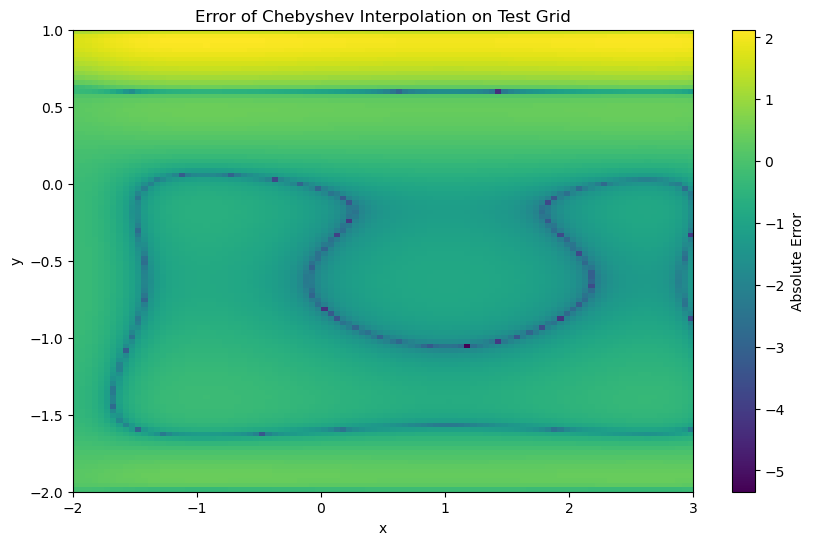

Max error on test grid: 1.33e+02
Median error on test grid 2.89e-01
Estimated Error: 2.62e+00
Relative Tolerance: 1.00e-03


In [482]:
# Want to calculate the error across an equally spaced test grid
x_test = np.linspace(ax + 0.1, bx-0.1, 100)
y_test = np.linspace(ay+0.1, by-0.1, 100)
X_test, Y_test = np.meshgrid(x_test, y_test, indexing='ij')
Z_test = f(X_test, Y_test)
# Evaluate the approximation on the test grid
rel_tol = 1e-3
interp2.optimize(rel_tol)
Z_approx = np.zeros_like(Z_test)
for i in range(X_test.shape[0]):
    for j in range(X_test.shape[1]):
        Z_approx[i, j] = interp2.evaluate(X_test[i, j], Y_test[i, j])
# Z_approx = clenshaw_2d(coeffs, X_test, Y_test,myMax1, ax = ax,bx =bx,ay=ay,by=by)
#Z_approx = interp.evaluate(x_test, y_test)
# Calculate the error on the test grid
Z_error = np.abs((Z_test - Z_approx)/Z_test)
# Plot the error
plt.figure(figsize=(10, 6))
plt.imshow(np.log10(Z_error), extent=(ax, bx, ay, by), origin='lower', aspect='auto', cmap='viridis')
plt.colorbar(label='Absolute Error')
plt.title('Error of Chebyshev Interpolation on Test Grid')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

print(f"Max error on test grid: {np.max(Z_error):.2e}")
print(f"Median error on test grid {np.median(Z_error):.2e}")
print(f"Estimated Error: {interp2.relative_error():.2e}")
print(f"Relative Tolerance: {rel_tol:.2e}")

In [483]:
from scipy.linalg import svd

def compress_chebyshev_coeffs(C, tol=1e-12):
    U, S, Vh = svd(C, full_matrices=False)
    r = np.sum(S > tol * S[0])  # choose rank adaptively
    return U[:, :r], S[:r], Vh[:r, :]

def eval_reduced_interpolant(U, S, V, x, y):
    result = 0.0
    nx = U.shape[0]
    ny = V.shape[1]
    for k in range(len(S)):
        u_val = clenshaw_1d(U[:, k], x,nx, a=ax, b=bx)
        v_val = clenshaw_1d(V[k, :], y,ny,a=ay, b=by)
        result += S[k] * u_val * v_val
    return result

In [484]:
U, S, V = compress_chebyshev_coeffs(coeffs, tol=1e-10)

U.shape[0], V.shape[1], len(S)

(6, 6, 1)

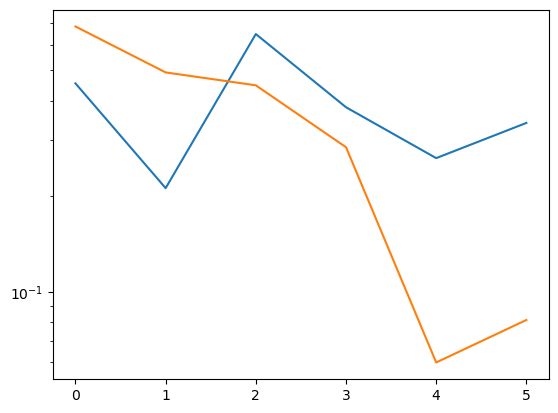

In [485]:
plt.plot(abs(U[:, 0]))
plt.plot(abs(V[0, :]))
plt.yscale('log')

In [486]:
# Evaluate at some point
x_eval, y_eval = 0.5, -0.5
approx = eval_reduced_interpolant(U, S, V, x_eval, y_eval)

# Compare to exact value
true_val = f(x_eval, y_eval)
error = abs(true_val - approx)

print(f"Approximation: {approx}")
print(f"True value:    {true_val}")
print(f"Absolute error: {error:.2e}")

Approximation: 0.5788276810275523
True value:    0.6065306597126334
Absolute error: 2.77e-02


Let's leave figuring out how to optimise the SVD evaluation until later. It's already a big improvement on its own and naturally lends itself to being precomputed in multiple directions pretty easily.

Focus on combining what we know into a simple to use interface like in the 1D case:

- A class that calculates the Coeffs
- Functions for the abs and rel errors
- Function to optimise based on the rel. tol
- Output the effective grid size
- Start testing that we recover the correct timings
- Set up the notebook to use this to compare with spline when computing FEW trajectories.
- Look into calculating PDs
- Want to save interpolant to a compressed file which can then be loaded